DI PROJECT KALI INI SAYA AKAN MEMBUAT MODEL MACHINE LEARNING UNTUK PREDIKSI CUACA YANG TERINTEGRASI KE WEB DAN IoT.

INFORMASI DATA SET SAYA SAYA MENGGUNAKAN 13.200 data DAN 10 FITURE

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

data_model = pd.read_csv('data_perkiraan_cuaca.csv')

print(data_model.head(10))

   Temperature  Humidity  Wind Speed  Precipitation (%)    Cloud Cover  \
0         14.0        73         9.5               82.0  partly cloudy   
1         39.0        96         8.5               71.0  partly cloudy   
2         30.0        64         7.0               16.0          clear   
3         38.0        83         1.5               82.0          clear   
4         27.0        74        17.0               66.0       overcast   
5         32.0        55         3.5               26.0       overcast   
6         -2.0        97         8.0               86.0       overcast   
7          3.0        85         6.0               96.0  partly cloudy   
8          3.0        83         6.0               66.0       overcast   
9         28.0        74         8.5              107.0          clear   

   Atmospheric Pressure  UV Index  Season  Visibility (km)  Location  \
0               1010.82         2  Winter              3.5    inland   
1               1011.43         7  Spring

In [2]:
data_model.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13200 entries, 0 to 13199
Data columns (total 11 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Temperature           13200 non-null  float64
 1   Humidity              13200 non-null  int64  
 2   Wind Speed            13200 non-null  float64
 3   Precipitation (%)     13200 non-null  float64
 4   Cloud Cover           13200 non-null  object 
 5   Atmospheric Pressure  13200 non-null  float64
 6   UV Index              13200 non-null  int64  
 7   Season                13200 non-null  object 
 8   Visibility (km)       13200 non-null  float64
 9   Location              13200 non-null  object 
 10  Weather Type          13200 non-null  object 
dtypes: float64(5), int64(2), object(4)
memory usage: 1.1+ MB


In [9]:
data_model.select_dtypes(include=['object'])

,Cloud Cover,Season,Location,Weather Type
0,partly cloudy,Winter,inland,Rainy
1,partly cloudy,Spring,inland,Cloudy
2,clear,Spring,mountain,Sunny
3,clear,Spring,coastal,Sunny
4,overcast,Winter,mountain,Rainy
...,...,...,...,...
13195,overcast,Summer,mountain,Rainy
13196,cloudy,Winter,coastal,Snowy
13197,overcast,Autumn,coastal,Cloudy
13198,overcast,Winter,inland,Snowy


In [11]:
data_model.select_dtypes(include=["float64", "int64"])

,Temperature,Humidity,Wind Speed,Precipitation (%),Atmospheric Pressure,UV Index,Visibility (km)
0,14.0,73,9.5,82.0,1010.82,2,3.5
1,39.0,96,8.5,71.0,1011.43,7,10.0
2,30.0,64,7.0,16.0,1018.72,5,5.5
3,38.0,83,1.5,82.0,1026.25,7,1.0
4,27.0,74,17.0,66.0,990.67,1,2.5
...,...,...,...,...,...,...,...
13195,10.0,74,14.5,71.0,1003.15,1,1.0
13196,-1.0,76,3.5,23.0,1067.23,1,6.0
13197,30.0,77,5.5,28.0,1012.69,3,9.0
13198,3.0,76,10.0,94.0,984.27,0,2.0


In [3]:
data_model.describe()

,Temperature,Humidity,Wind Speed,Precipitation (%),Atmospheric Pressure,UV Index,Visibility (km)
count,13200.000000,13200.000000,13200.000000,13200.000000,13200.000000,13200.000000,13200.000000
mean,19.127576,68.710833,9.832197,53.644394,1005.827896,4.005758,5.462917
std,17.386327,20.194248,6.908704,31.946541,37.199589,3.856600,3.371499
min,-25.000000,20.000000,0.000000,0.000000,800.120000,0.000000,0.000000
25%,4.000000,57.000000,5.000000,19.000000,994.800000,1.000000,3.000000
50%,21.000000,70.000000,9.000000,58.000000,1007.650000,3.000000,5.000000
75%,31.000000,84.000000,13.500000,82.000000,1016.772500,7.000000,7.500000
max,109.000000,109.000000,48.500000,109.000000,1199.210000,14.000000,20.000000


In [4]:
data_model.isnull().sum()

Temperature             0
Humidity                0
Wind Speed              0
Precipitation (%)       0
Cloud Cover             0
Atmospheric Pressure    0
UV Index                0
Season                  0
Visibility (km)         0
Location                0
Weather Type            0
dtype: int64

In [5]:
data_model.duplicated().sum()

np.int64(0)

APLITING DATA

In [6]:
x = data_model.drop(["Weather Type"], axis=1)
y = data_model["Weather Type"]

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size= 0.3, random_state=42)

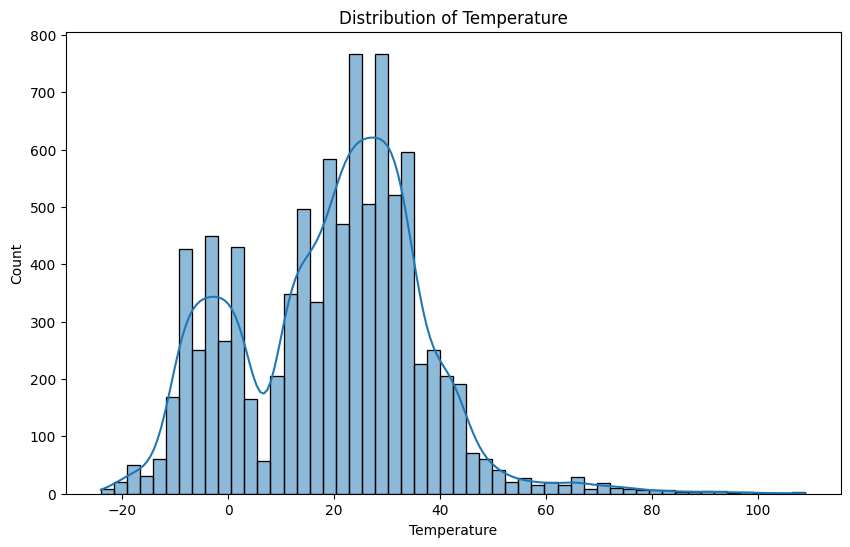

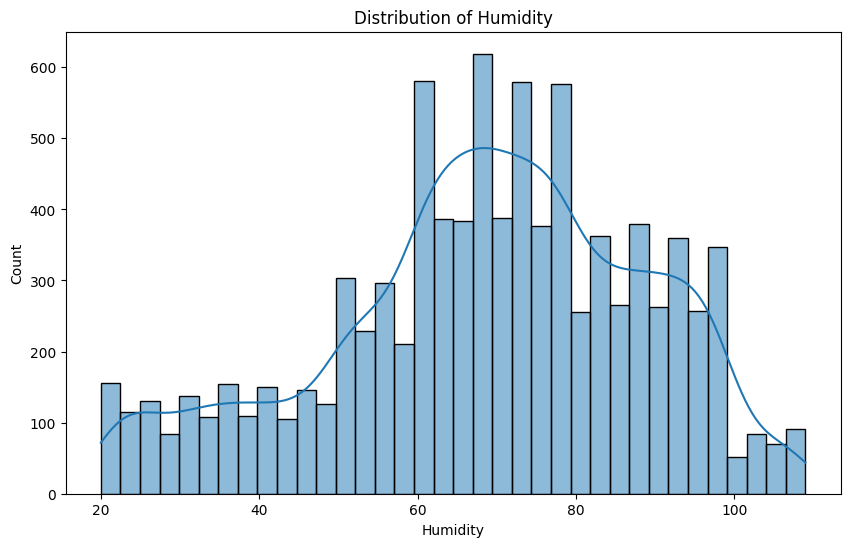

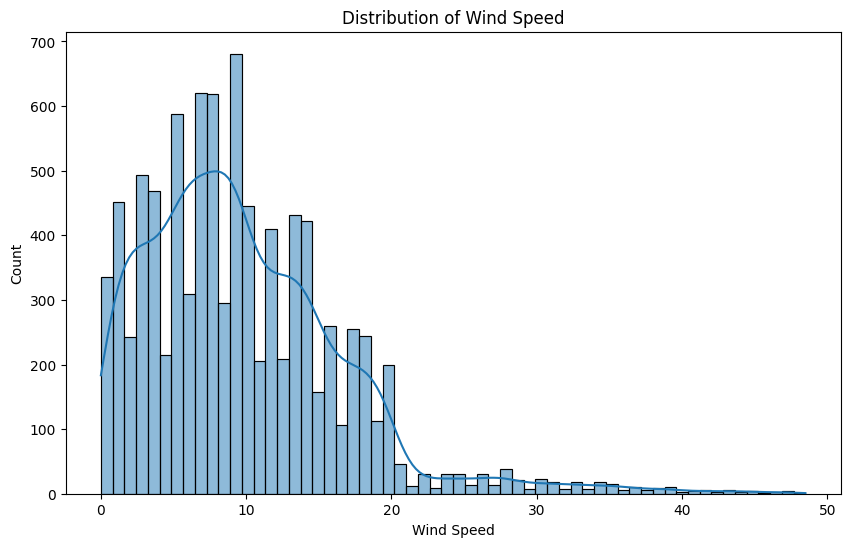

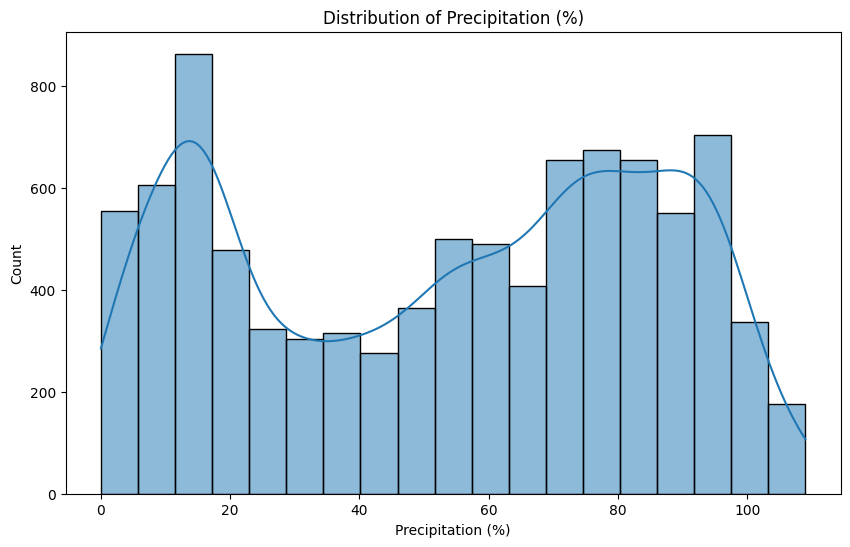

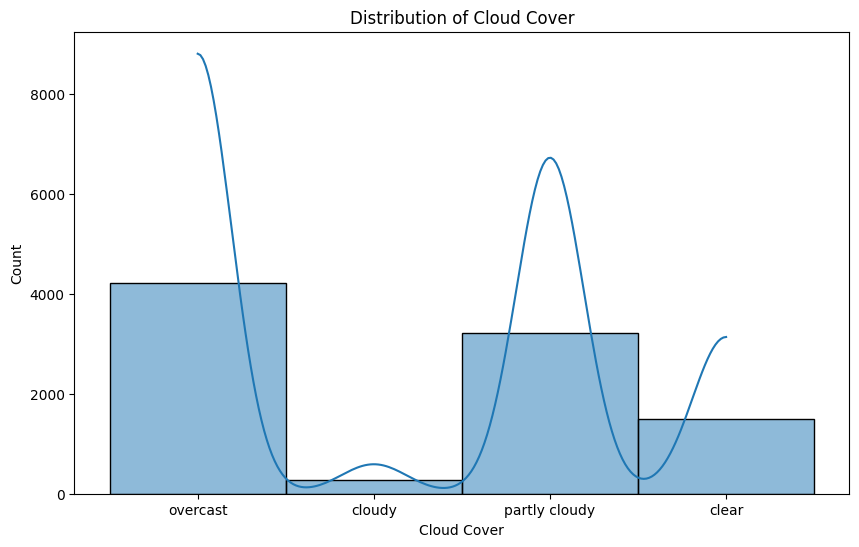

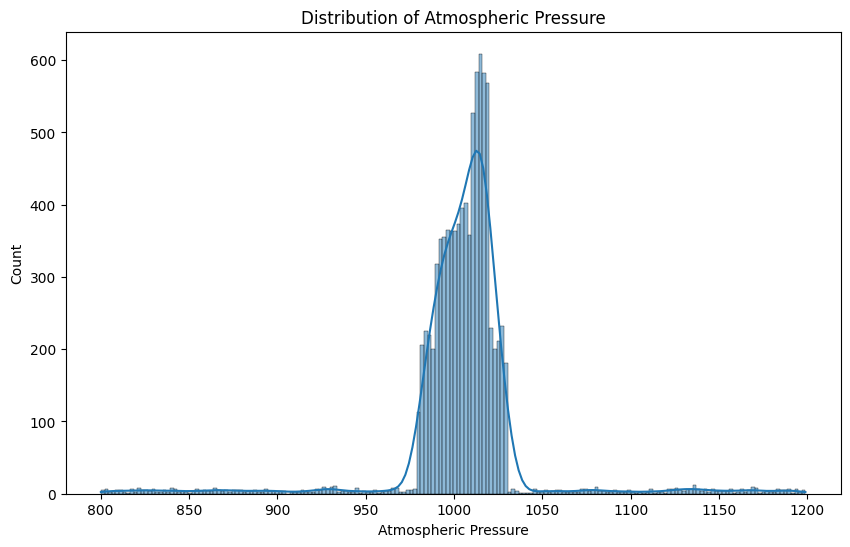

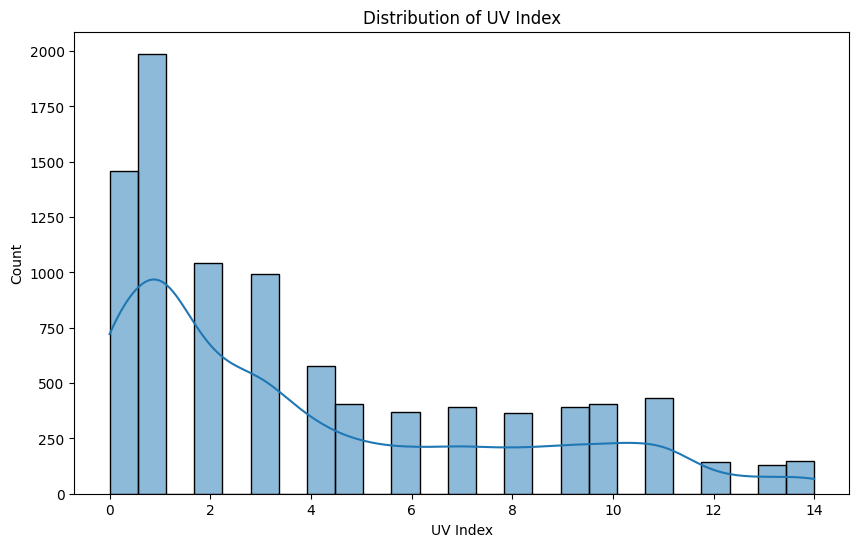

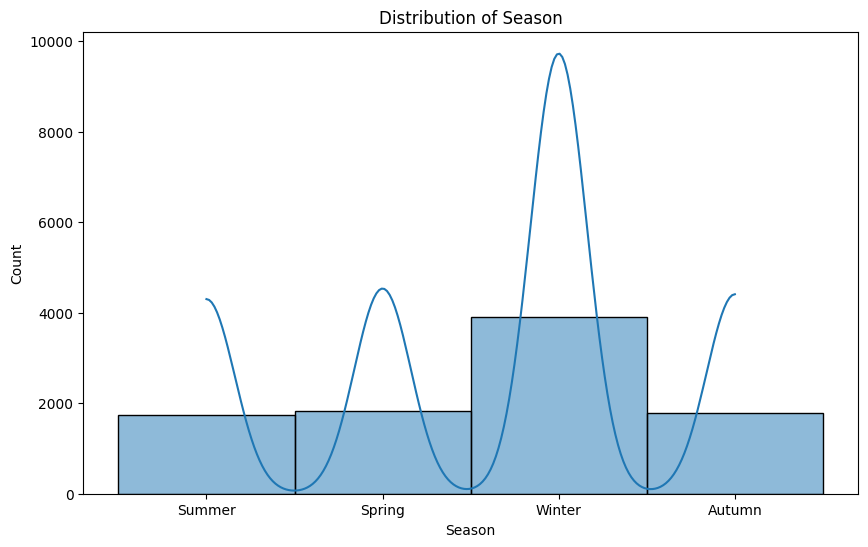

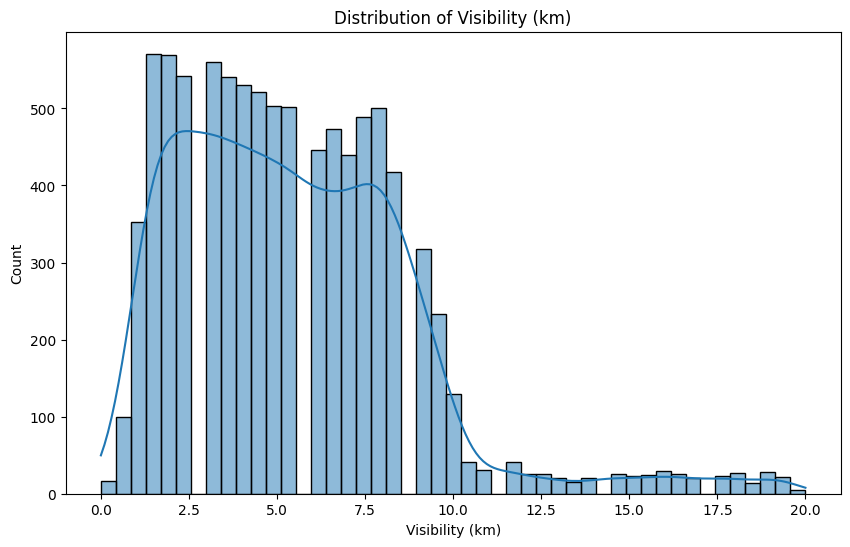

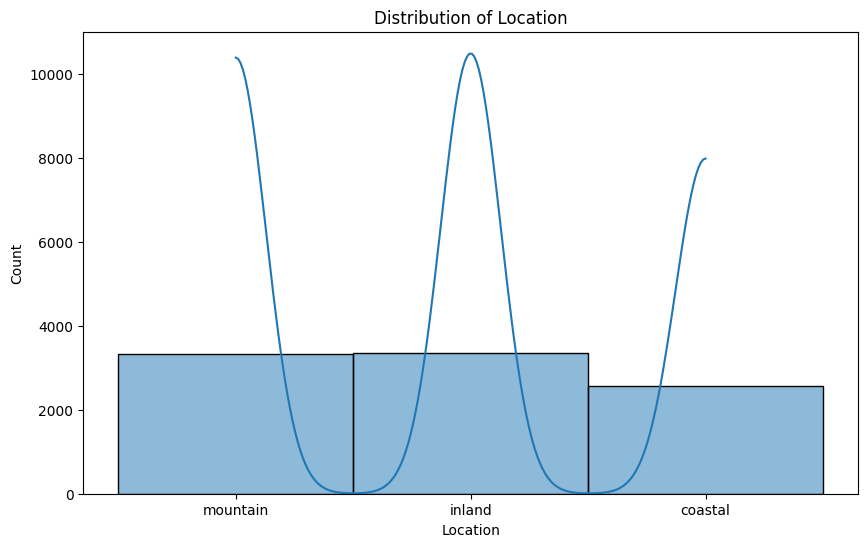

In [7]:
for i in x_train.columns:
    plt.figure(figsize=(10,6))
    sns.histplot(x_train[i], kde=True)
    plt.title(f'Distribution of {i}')
    plt.show()

DISTRIBUSI FREKUENSI 

MEMISAHKAN DATA KUALITATIF DAN KUANTITATIF

In [17]:
x_train_object = data_model.select_dtypes(include=['object'])

x_train_numerik = data_model.select_dtypes(include=["float64", "int64"])

In [15]:
for i in x_train_object.columns:
    print(x_train_object[i].value_counts())
    print(f' distribusi data untuk variabel {i}')

Cloud Cover
overcast         6090
partly cloudy    4560
clear            2139
cloudy            411
Name: count, dtype: int64
 distribusi data untuk variabel Cloud Cover
Season
Winter    5610
Spring    2598
Autumn    2500
Summer    2492
Name: count, dtype: int64
 distribusi data untuk variabel Season
Location
inland      4816
mountain    4813
coastal     3571
Name: count, dtype: int64
 distribusi data untuk variabel Location
Weather Type
Rainy     3300
Cloudy    3300
Sunny     3300
Snowy     3300
Name: count, dtype: int64
 distribusi data untuk variabel Weather Type


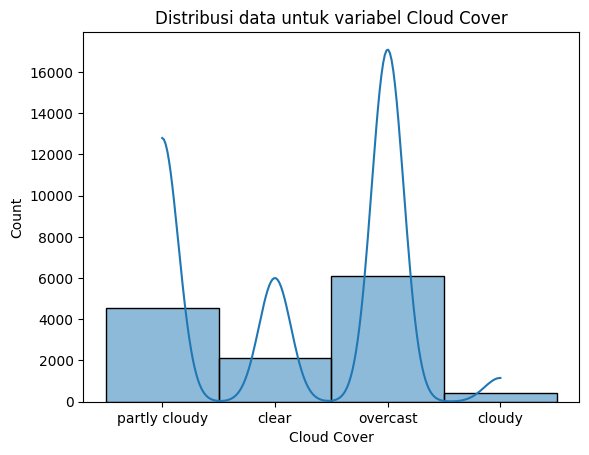

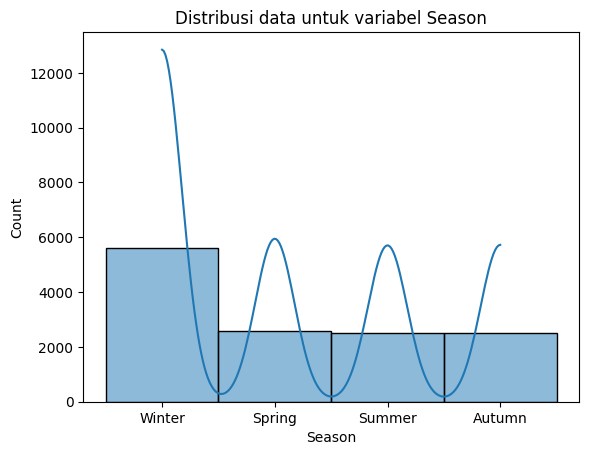

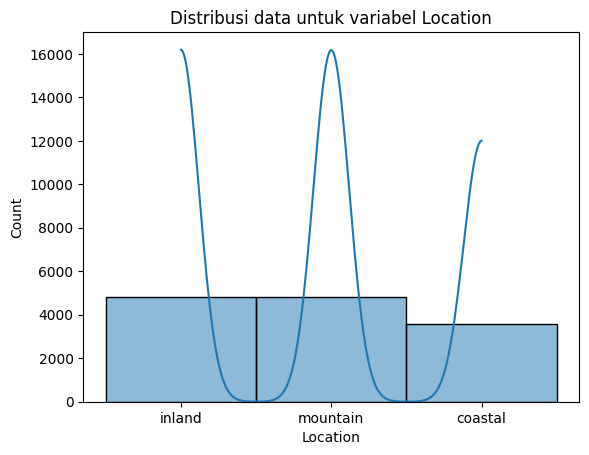

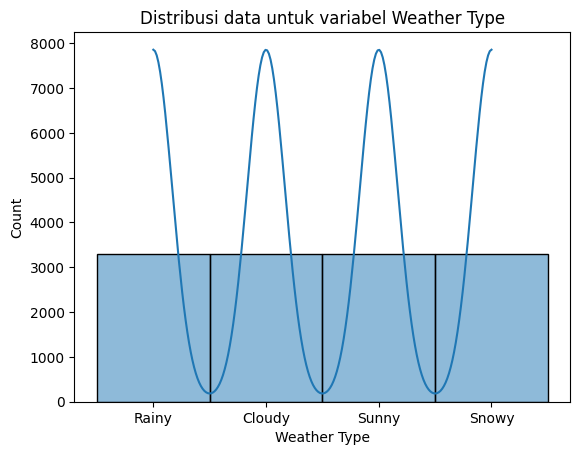

In [16]:
for i in x_train_object.columns:
    plt.Figure(figsize=(10, 6))
    plt.title(f'Distribusi data untuk variabel {i}')
    sns.histplot(data=x_train_object, x=i, kde=True)
    plt.show()

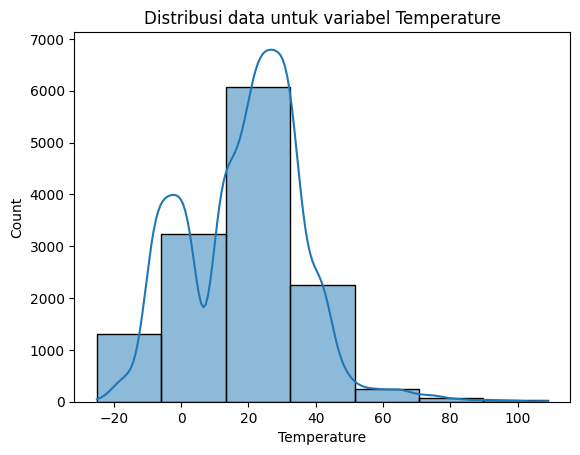

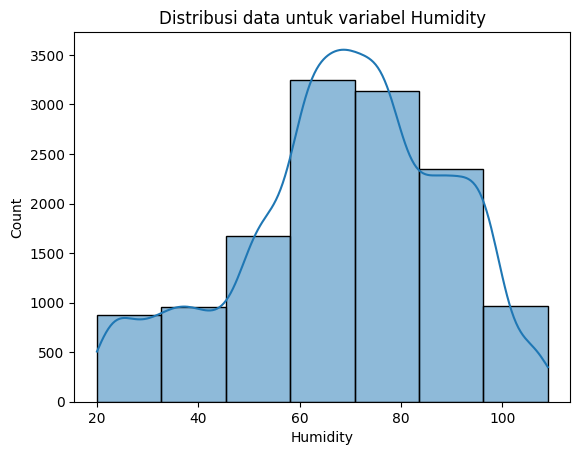

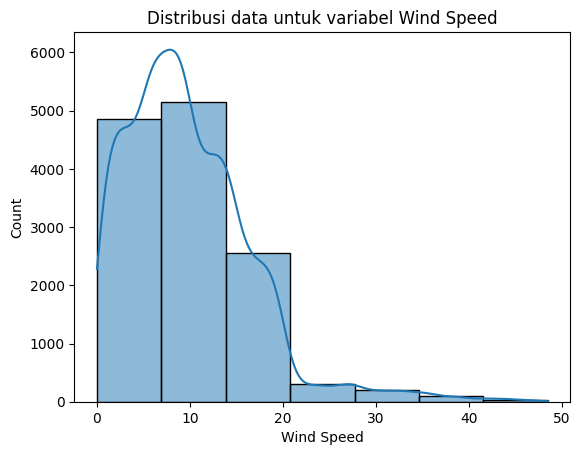

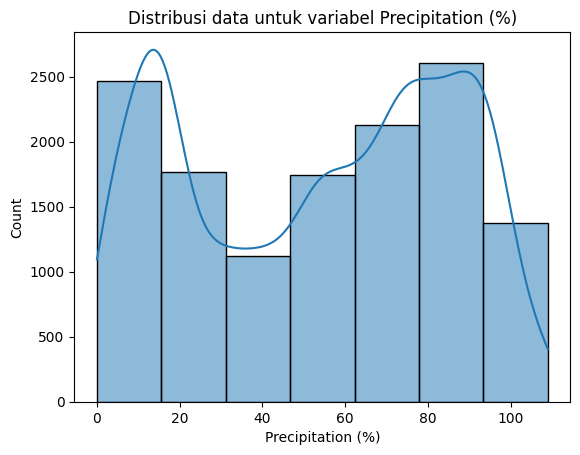

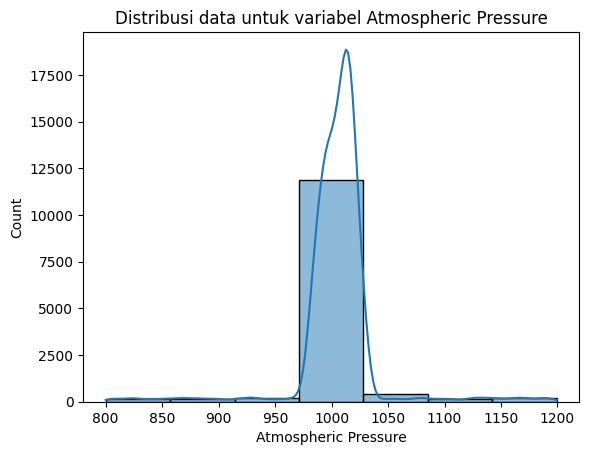

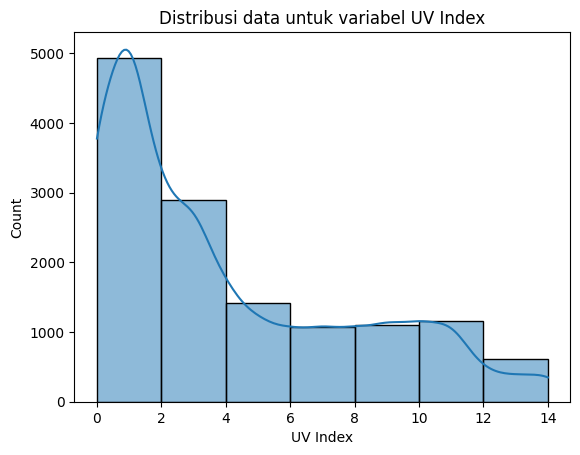

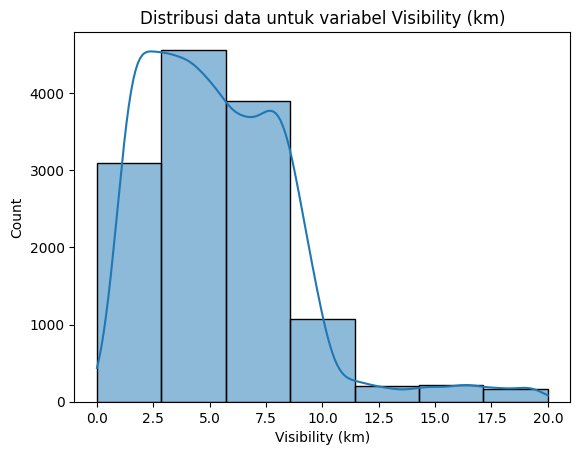

In [20]:
for i in x_train_numerik.columns:
    plt.Figure(figsize=(10, 6))
    plt.title(f'Distribusi data untuk variabel {i}')
    sns.histplot(data=x_train_numerik, x=i,bins=7, kde=True)
    plt.show()